# Analyse du Data Drift et monitoring du modèle de scoring

**Auteur :** Marin Ramananjaona  
**Projet :** Confirmez vos compétences en MLOps — Partie 2

## Objectif

Comparer les données reçues par l’API à une référence pour détecter
des changements de distribution et de disponibilité des variables.
Observer également les scores prédits et les performances de l’API.

## Données

- Référence : 5 000 clients.
- Production stable : 1 000 clients distincts de la référence.
- Production avec dérive : les mêmes 1 000 clients, modifiés artificiellement.

Les données de production analysées ont été enregistrées par l’API
dans SQLite puis exportées.

Le scénario de dérive applique :
- une réduction de 40 % des valeurs renseignées de EXT_SOURCE_2 ;
- la suppression de 20 % des valeurs renseignées de EXT_SOURCE_3.

EXT_SOURCE_1 sert de variable témoin non modifiée.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import ks_2samp

# Fonctionne depuis la racine du dépôt ou le dossier notebooks.
ROOT = Path.cwd()
if not (ROOT / "models").is_dir():
    ROOT = ROOT.parent

if not (ROOT / "models").is_dir():
    raise RuntimeError("Ouvrir ce notebook depuis le dépôt du projet.")

reference = pd.read_parquet(
    ROOT / "data/reference/reference_features.parquet"
)

manifest = json.loads(
    (ROOT / "data/production/exports/monitoring_exports.json")
    .read_text(encoding="utf-8")
)

features = {}
events = {}

for scenario in ["stable", "drift"]:
    features[scenario] = pd.read_parquet(
        ROOT / manifest[scenario]["features"]
    )
    events[scenario] = pd.read_parquet(
        ROOT / manifest[scenario]["events"]
    )

display(pd.DataFrame([
    {
        "ensemble": "reference",
        "clients": len(reference),
        "variables": reference.shape[1],
    },
    *[
        {
            "ensemble": scenario,
            "clients": len(features[scenario]),
            "variables": features[scenario].shape[1],
        }
        for scenario in ["stable", "drift"]
    ],
]))

,ensemble,clients,variables
0,reference,5000,541
1,stable,1000,541
2,drift,1000,541


## Méthode de détection

L’analyse porte sur trois variables numériques :
EXT_SOURCE_1, EXT_SOURCE_2 et EXT_SOURCE_3.

Deux contrôles sont utilisés :

1. Distance de Kolmogorov-Smirnov (KS) entre les distributions
   des valeurs renseignées.
2. Variation du taux de valeurs manquantes.

Seuils indicatifs du PoC :
- alerte si la distance KS dépasse 0,10 ;
- alerte si la variation absolue des valeurs manquantes dépasse 5 points.

Ces seuils sont des choix de démonstration, à calibrer avant un usage réel.
Nous utilisons la distance KS comme mesure d’écart, sans interpréter
la p-value comme un critère de décision.

In [2]:
variables = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
rows = []

for scenario, current in features.items():
    for variable in variables:
        ref_values = reference[variable].dropna()
        current_values = current[variable].dropna()

        distance = (
            float(ks_2samp(
                ref_values,
                current_values,
                method="asymp",
            ).statistic)
            if len(ref_values) and len(current_values)
            else np.nan
        )

        missing_ref = reference[variable].isna().mean()
        missing_current = current[variable].isna().mean()
        difference = missing_current - missing_ref

        rows.append({
            "scenario": scenario,
            "variable": variable,
            "distance_KS": distance,
            "distribution": (
                "NON CALCULABLE" if pd.isna(distance)
                else "ALERTE" if distance > 0.10
                else "OK"
            ),
            "manquants_reference_pct": 100 * missing_ref,
            "manquants_production_pct": 100 * missing_current,
            "ecart_points": 100 * difference,
            "valeurs_manquantes": (
                "ALERTE" if abs(difference) > 0.05 else "OK"
            ),
        })

drift_results = pd.DataFrame(rows)
display(drift_results.round(4))

,scenario,variable,distance_KS,distribution,manquants_reference_pct,manquants_production_pct,ecart_points,valeurs_manquantes
0,stable,EXT_SOURCE_1,0.0383,OK,55.72,55.0,-0.72,OK
1,stable,EXT_SOURCE_2,0.0411,OK,0.18,0.6,0.42,OK
2,stable,EXT_SOURCE_3,0.0319,OK,19.52,21.2,1.68,OK
3,drift,EXT_SOURCE_1,0.0383,OK,55.72,55.0,-0.72,OK
4,drift,EXT_SOURCE_2,0.6499,ALERTE,0.18,0.6,0.42,OK
5,drift,EXT_SOURCE_3,0.0379,OK,19.52,36.9,17.38,ALERTE


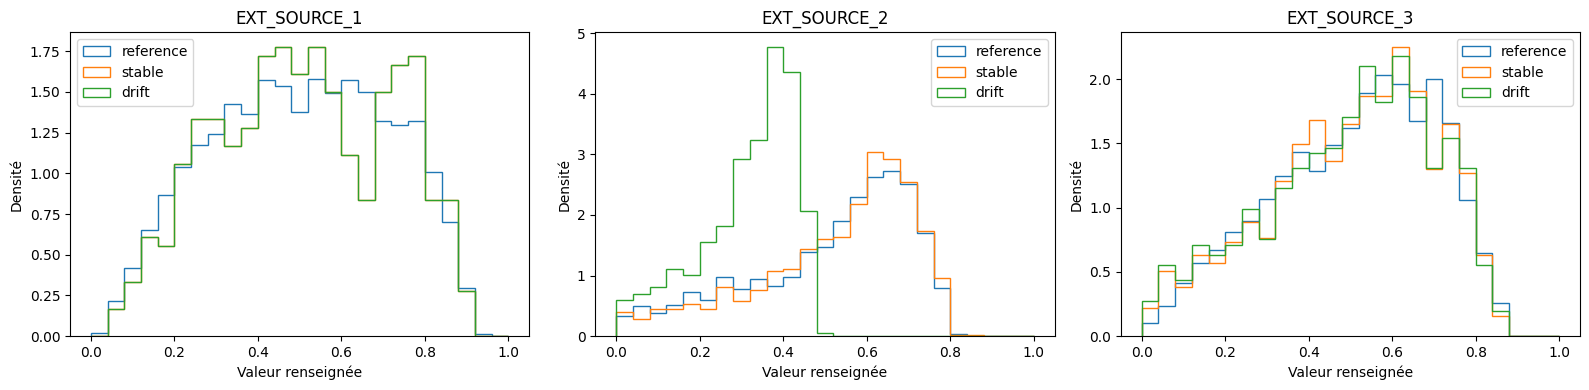

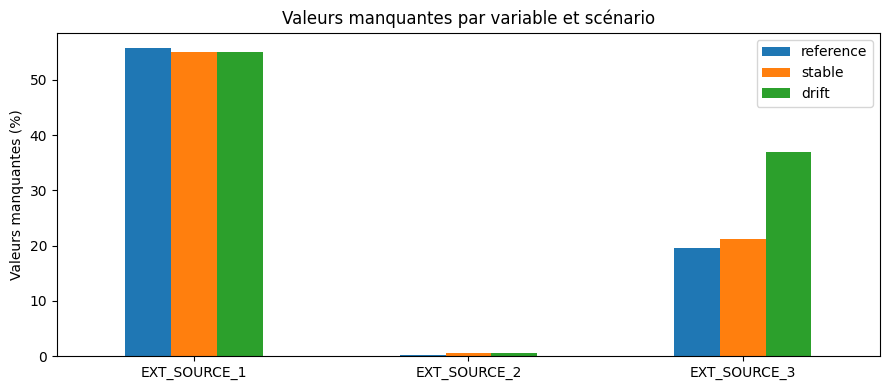

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bins = np.linspace(0, 1, 26)

for ax, variable in zip(axes, variables):
    datasets = {"reference": reference, **features}

    for name, frame in datasets.items():
        ax.hist(
            frame[variable].dropna(),
            bins=bins,
            density=True,
            histtype="step",
            label=name,
        )

    ax.set_title(variable)
    ax.set_xlabel("Valeur renseignée")
    ax.set_ylabel("Densité")
    ax.legend()

plt.tight_layout()
plt.show()

missing_rates = pd.DataFrame({
    "reference": reference[variables].isna().mean() * 100,
    "stable": features["stable"][variables].isna().mean() * 100,
    "drift": features["drift"][variables].isna().mean() * 100,
})

missing_rates.plot.bar(figsize=(9, 4))
plt.title("Valeurs manquantes par variable et scénario")
plt.ylabel("Valeurs manquantes (%)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Interprétation du drift

Sur les exécutions étudiées :

- Le scénario stable ne déclenche aucune alerte sur les trois variables.
- EXT_SOURCE_2 déclenche une alerte de distribution : distance KS
  d’environ 0,650.
- EXT_SOURCE_3 déclenche une alerte de disponibilité : son taux de
  valeurs manquantes atteint 36,9 %, contre 19,52 % dans la référence,
  soit une hausse de 17,38 points.
- La distribution des valeurs renseignées de EXT_SOURCE_3 reste proche
  de la référence. Le contrôle des valeurs manquantes est donc nécessaire
  en complément de celui des distributions.
- EXT_SOURCE_1, variable témoin, ne déclenche pas d’alerte.

Ces résultats permettent de détecter les deux modifications introduites.

,scenario,appels,erreurs_pct,inference_mediane_ms,traitement_median_ms,latence_mediane_ms,latence_p95_ms,alerte_erreurs,alerte_latence,score_moyen,classe_1_pct
0,stable,1000,0.0,0.5778,3.6460,6.1250,7.5937,False,False,0.3696,27.5
1,drift,1000,0.0,0.5663,3.6057,6.0273,7.7632,False,False,0.3721,27.5


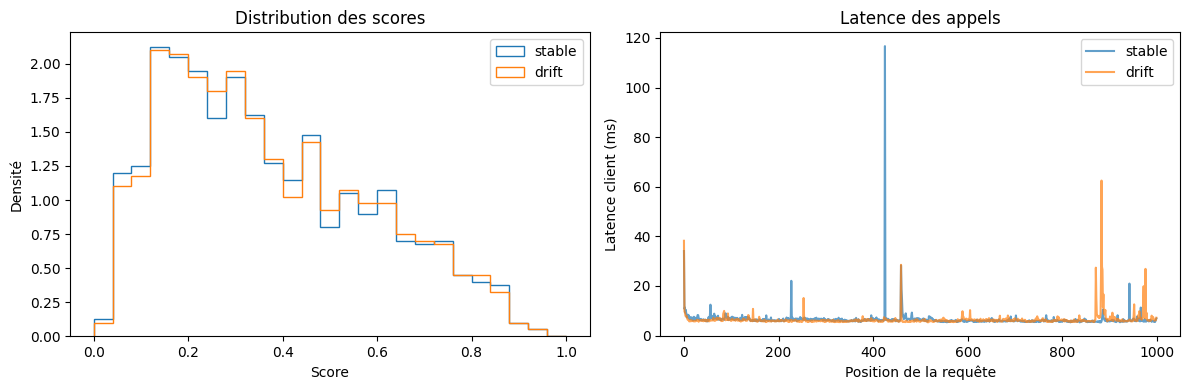

In [4]:
operation_rows = []

for scenario, frame in events.items():
    error_rate = 100 * (frame["status_code"] >= 400).mean()
    latency_p95 = frame["client_latency_ms"].quantile(0.95)

    operation_rows.append({
        "scenario": scenario,
        "appels": len(frame),
        "erreurs_pct": error_rate,
        "inference_mediane_ms": frame["inference_ms"].median(),
        "traitement_median_ms": frame["processing_ms"].median(),
        "latence_mediane_ms": frame["client_latency_ms"].median(),
        "latence_p95_ms": latency_p95,
        "alerte_erreurs": error_rate > 1,
        "alerte_latence": latency_p95 > 100,
        "score_moyen": frame["score"].mean(),
        "classe_1_pct": 100 * frame["prediction"].mean(),
    })

display(pd.DataFrame(operation_rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for scenario, frame in events.items():
    axes[0].hist(
        frame["score"],
        bins=np.linspace(0, 1, 26),
        density=True,
        histtype="step",
        label=scenario,
    )
    axes[1].plot(
        frame["row_position"],
        frame["client_latency_ms"],
        alpha=0.7,
        label=scenario,
    )

axes[0].set_title("Distribution des scores")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Densité")
axes[0].legend()

axes[1].set_title("Latence des appels")
axes[1].set_xlabel("Position de la requête")
axes[1].set_ylabel("Latence client (ms)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [5]:
paired = events["stable"][
    ["row_position", "score", "prediction"]
].merge(
    events["drift"][["row_position", "score", "prediction"]],
    on="row_position",
    suffixes=("_stable", "_drift"),
    validate="one_to_one",
)

assert len(paired) == len(events["stable"]) == len(events["drift"])

changed = (
    paired["prediction_stable"] != paired["prediction_drift"]
).sum()

print(f"Clients comparés : {len(paired)}")
print(f"Décisions modifiées entre les scénarios : {changed}")
print(
    "Variation absolue moyenne du score :",
    (paired["score_drift"] - paired["score_stable"]).abs().mean(),
)

Clients comparés : 1000
Décisions modifiées entre les scénarios : 2
Variation absolue moyenne du score : 0.0044428465734776676


## Interprétation du monitoring opérationnel

Les deux exécutions comportent chacune 1 000 appels réussis.
Leur latence p95 reste inférieure au seuil indicatif de 100 ms.
Le seuil indicatif du taux d’erreur est fixé à 1 %.

Les durées mesurées sont distinctes :
- inférence : calcul du modèle ;
- traitement serveur : traitement mesuré avant l’écriture SQLite ;
- latence client : appel HTTP jusqu’à réception de la réponse.

Les scores moyens sont proches et la proportion de classes 1 est
identique : 27,5 %. Pourtant, deux clients changent de décision entre
les scénarios. Un indicateur global peut donc masquer des changements
individuels.

Ces mesures correspondent aux exécutions de monitoring avant optimisation.
La comparaison avant/après optimisation est présentée dans
reports/performance/optimization_report.md.

## Actions à envisager

- Alerte de distribution : vérifier la population reçue et la préparation
  des variables.
- Hausse des valeurs manquantes : vérifier la source de données et
  les transformations.
- Hausse des erreurs ou latences : examiner les logs et les ressources.
- Avant un réentraînement : identifier la cause de la dérive et
  évaluer son impact.

## Limites

- L’analyse couvre trois variables sur les 541 du modèle.
- Les seuils sont indicatifs et ne sont pas calibrés pour une exploitation réelle.
- Les modifications sont artificielles ; les éventuelles variables dérivées
  ne sont pas recalculées.
- Les clients de référence et de production stable sont distincts,
  mais proviennent du même fichier du projet précédent.
- Le taux d’erreur porte sur les deux exécutions sélectionnées,
  pas sur l’ensemble de l’historique.
- Les appels sont locaux et séquentiels : ce n’est pas un test de charge.
- Les classes prédites ne sont pas des défauts observés.
- Sans résultats réels de remboursement, on ne peut pas mesurer
  une baisse de précision en production.

## Conclusion

Le monitoring détecte la modification de distribution de EXT_SOURCE_2
et la dégradation de disponibilité de EXT_SOURCE_3.
Le scénario stable et la variable témoin ne déclenchent pas d’alerte
avec les seuils retenus.